# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [2]:
# 데이터 로드
data = pd.read_csv("/content/abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [5]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [6]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.3, random_state=42)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [7]:
#필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [9]:
#릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3)
ridge.fit(X_train, y_train)

#예측값 구하기
pred = ridge.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
pred_age = pred + 1.5
y_test_age = y_test + 1.5

#MSE와 RMSE구하기
mse = mean_squared_error(y_test_age, pred_age)
rmse = np.sqrt(mse)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse, rmse))

MSE: 4.772, RMSE: 2.185


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [11]:
data.columns

coef = pd.Series(ridge.coef_, index=data.columns)
coef.sort_values(ascending=False)

,0
Shell weight,9.360811
Height,8.886406
Whole weight,8.625577
Diameter,7.950942
Length,2.286643
M,0.309268
F,0.223771
I,-0.533039
Viscera weight,-8.644888
Shucked weight,-20.040631


3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [12]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [15]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함
for alpha in alphas:
    ridge_cv = Ridge(alpha=alpha)

    #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
    neg_mse_scores = cross_val_score(ridge_cv, X, y, scoring='neg_mean_squared_error', cv=5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print('alpha {0} 일 때 5 folds의 평균 RMSE: {1:.3f}'.format(alpha, avg_rmse))


alpha 0 일 때 5 folds의 평균 RMSE: 2.245
alpha 0.1 일 때 5 folds의 평균 RMSE: 2.237
alpha 1 일 때 5 folds의 평균 RMSE: 2.230
alpha 10 일 때 5 folds의 평균 RMSE: 2.337
alpha 100 일 때 5 folds의 평균 RMSE: 2.621


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [16]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [17]:
#모델 생성 및 훈련
xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
xgb.fit(X_train, y_train)

#예측값 구하기
xgb_pred = xgb.predict(X_test)
xgb_pred_age = xgb_pred + 1.5

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
y_test_age = y_test + 1.5

#MSE와 RMSE 구하기
xgb_mse = mean_squared_error(y_test_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(xgb_mse, xgb_rmse))


MSE: 4.757, RMSE: 2.181


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

Text(0.5, 1.0, 'XGBRegressor Feature Importances')

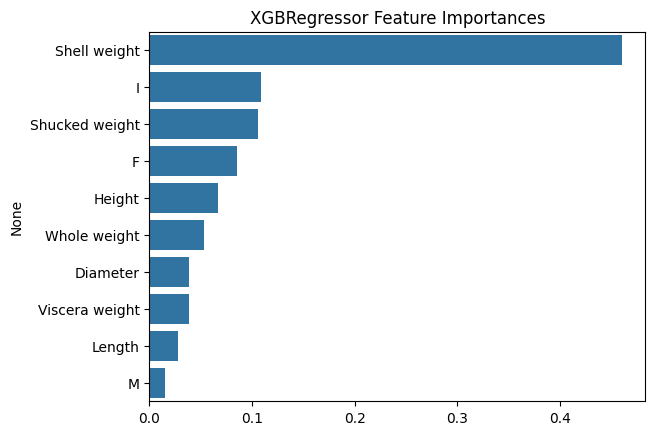

In [19]:
import seaborn as sns
%matplotlib inline

feature_importance = pd.Series(xgb.feature_importances_, index=data.columns)
feature_importance = feature_importance.sort_values(ascending=False)

ax = sns.barplot(x=feature_importance.values, y=feature_importance.index)
ax.set_title('XGBRegressor Feature Importances')

---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [20]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [21]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [22]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [23]:
lr = LogisticRegression(max_iter=10000)
lr.fit(x_train, y_train)

LogisticRegression(max_iter=10000)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [24]:
#기울기
lr.coef_

array([[ 0.42439298,  0.54744452,  0.62026175, -0.25946906, -0.00207495,
         0.25257608,  0.75790461,  0.09118418,  0.14341218,  0.1758945 ,
        -0.01150508,  0.51869373,  0.00865839],
       [-0.61350726, -0.91046142, -0.69744893,  0.14881052, -0.04174846,
         0.31231432,  0.15345516,  0.03003637,  0.39268846, -0.9168763 ,
         0.32597234,  0.13224331, -0.00767599],
       [ 0.18911428,  0.3630169 ,  0.07718717,  0.11065854,  0.0438234 ,
        -0.5648904 , -0.91135977, -0.12122055, -0.53610064,  0.7409818 ,
        -0.31446726, -0.65093704, -0.0009824 ]])

In [25]:
#절편
lr.intercept_

array([-13.57617163,  21.30986693,  -7.73369529])

3-3) 모델의 정확도를 구하세요.

In [26]:
#모델의 예측값 구하기
y_pred = lr.predict(x_test)

#모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred)
print('정확도: {0:.4f}'.format(accuracy))


정확도: 0.9630
